In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder

plt.style.use('default')

## **Problem 1 to 2:**

**Dataset link:** https://rb.gy/gsmddu

**Add a label to every axis and add a proper title for the charts (For every subplot, it is applicable). Also add proper labels if there are multiple representations.** Then, you can customize it as your wish.

### **Problem-1:** Make a subplots which have 2 plots.

- For the first chart, draw a scatter plot "*Monitored Cap.(MW)*" vs "*Total Cap. Under Maintenance (MW)*" of top 5 most frequent power stations. Then draw the lines which indicate the average values of these two columns. Change the colors according to the names of the Power Stations.
- For the second chart, draw a scatter plot "*Monitored Cap. (MW)*" vs "*Actual(MU)*" of the top 5 most frequent power stations. Also draw the lines which indicates the average values of these two columns. Change the colors according to the names of the Power Stations.


In [67]:
power_gen = pd.read_csv('/content/PowerGeneration - PowerGeneration.csv')

In [68]:
power_gen.head(3)

,Dates,Power Station,Monitored Cap.(MW),Total Cap. Under Maintenace (MW),Planned Maintanence (MW),Forced Maintanence(MW),Other Reasons (MW),Programme or Expected(MU),Actual(MU),Excess(+) / Shortfall (-),Deviation
0,2017-09-01,Delhi,2235.4,135.0,0.0,135.0,0,13,18,5.00,0.0
1,2017-09-01,Haryana,2720.0,2470.0,0.0,2470.0,0,28,7,-21.80,0.0
2,2017-09-01,Himachal Pradesh,3378.0,379.0,0.0,231.0,0,40,46,5.63,0.0


In [69]:
top_5 = power_gen['Power Station'].value_counts().head(5).reset_index()['Power Station'].tolist()
top_5

['NTPC Ltd.', 'NHPC', 'NPCIL', 'GMR ENERG', 'APL']

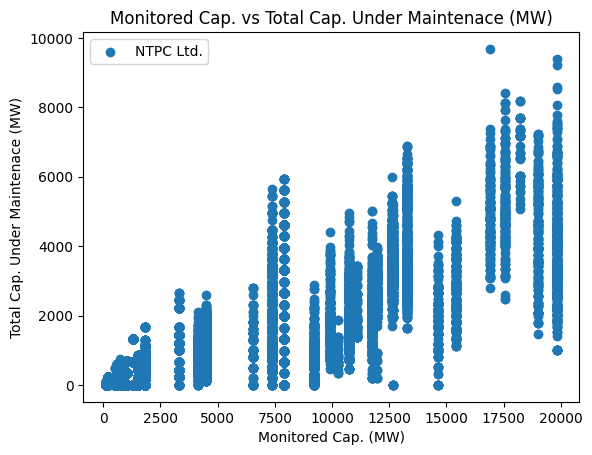

In [70]:
plt.scatter(
    power_gen[power_gen['Power Station'].isin(top_5)]['Monitored Cap.(MW)'],
    power_gen[power_gen['Power Station'].isin(top_5)]['Total Cap. Under Maintenace (MW)']
    )

plt.title("Monitored Cap. vs Total Cap. Under Maintenace (MW)")
plt.xlabel("Monitored Cap. (MW)")
plt.ylabel("Total Cap. Under Maintenace (MW)")
plt.legend(top_5)

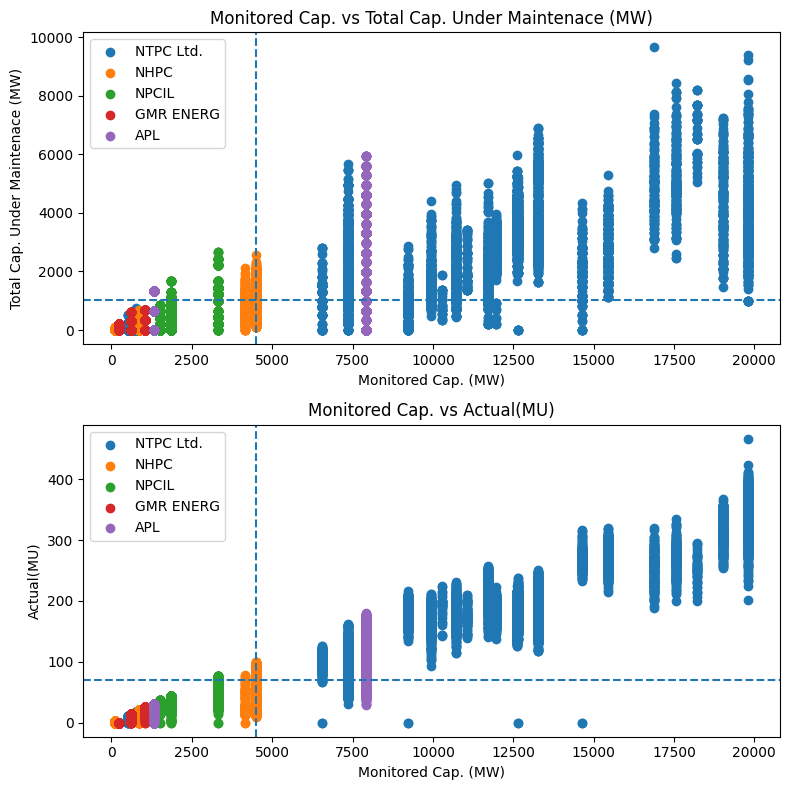

In [71]:
fig, ax = plt.subplots(2,1,figsize=(8,8))

for station in top_5:
  ax[0].scatter(
		power_gen[power_gen['Power Station'] == station]['Monitored Cap.(MW)'],
		power_gen[power_gen['Power Station'] == station]['Total Cap. Under Maintenace (MW)']
    )

ax[0].set_title("Monitored Cap. vs Total Cap. Under Maintenace (MW)")
ax[0].set_xlabel("Monitored Cap. (MW)")
ax[0].set_ylabel("Total Cap. Under Maintenace (MW)")
ax[0].legend(top_5)

avg_x1 = ax[0].axvline(power_gen[power_gen['Power Station'].isin(top_5)]['Monitored Cap.(MW)'].mean(), linestyle='--')
avg_y1 = ax[0].axhline(power_gen[power_gen['Power Station'].isin(top_5)]['Total Cap. Under Maintenace (MW)'].mean(), linestyle='--')

for station in top_5:
  ax[1].scatter(
		power_gen[power_gen['Power Station'] == station]['Monitored Cap.(MW)'],
		power_gen[power_gen['Power Station'] == station]['Actual(MU)']
    )
ax[1].set_title("Monitored Cap. vs Actual(MU)")
ax[1].set_xlabel("Monitored Cap. (MW)")
ax[1].set_ylabel("Actual(MU)")
ax[1].legend(top_5)

avg_x2 = ax[1].axvline(power_gen[power_gen['Power Station'].isin(top_5)]['Monitored Cap.(MW)'].mean(), linestyle='--')
avg_y2 = ax[1].axhline(power_gen[power_gen['Power Station'].isin(top_5)]['Actual(MU)'].mean(), linestyle='--')


plt.tight_layout()

### **Problem-2:** Draw a 3D Scatter plot between "*Monitored Cap.(MW)*", "*Total Cap. Under Maintenace (MW)*" and "*Forced Maintanence(MW)*"

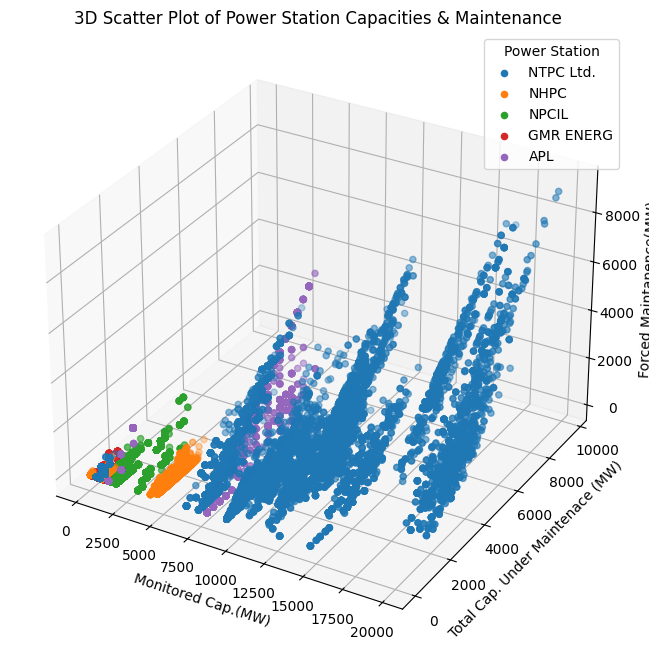

In [72]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"}, figsize=(10, 8))

for station in top_5:
    station_data = power_gen[power_gen['Power Station'] == station]
    ax.scatter(
        station_data['Monitored Cap.(MW)'],
        station_data['Total Cap. Under Maintenace (MW)'],
        station_data['Forced Maintanence(MW)'],
        label=station
    )

ax.set_xlabel('Monitored Cap.(MW)')
ax.set_ylabel('Total Cap. Under Maintenace (MW)')
ax.set_zlabel('Forced Maintanence(MW)')
ax.set_title('3D Scatter Plot of Power Station Capacities & Maintenance')
ax.legend(title='Power Station')

plt.show()

### **Problem-3:** Make a 3D *Surface* plot of this below mathematical equation.

$$z = |x| - |y|$$

[-5.         -4.8989899  -4.7979798  -4.6969697  -4.5959596  -4.49494949
 -4.39393939 -4.29292929 -4.19191919 -4.09090909 -3.98989899 -3.88888889
 -3.78787879 -3.68686869 -3.58585859 -3.48484848 -3.38383838 -3.28282828
 -3.18181818 -3.08080808 -2.97979798 -2.87878788 -2.77777778 -2.67676768
 -2.57575758 -2.47474747 -2.37373737 -2.27272727 -2.17171717 -2.07070707
 -1.96969697 -1.86868687 -1.76767677 -1.66666667 -1.56565657 -1.46464646
 -1.36363636 -1.26262626 -1.16161616 -1.06060606 -0.95959596 -0.85858586
 -0.75757576 -0.65656566 -0.55555556 -0.45454545 -0.35353535 -0.25252525
 -0.15151515 -0.05050505  0.05050505  0.15151515  0.25252525  0.35353535
  0.45454545  0.55555556  0.65656566  0.75757576  0.85858586  0.95959596
  1.06060606  1.16161616  1.26262626  1.36363636  1.46464646  1.56565657
  1.66666667  1.76767677  1.86868687  1.96969697  2.07070707  2.17171717
  2.27272727  2.37373737  2.47474747  2.57575758  2.67676768  2.77777778
  2.87878788  2.97979798  3.08080808  3.18181818  3

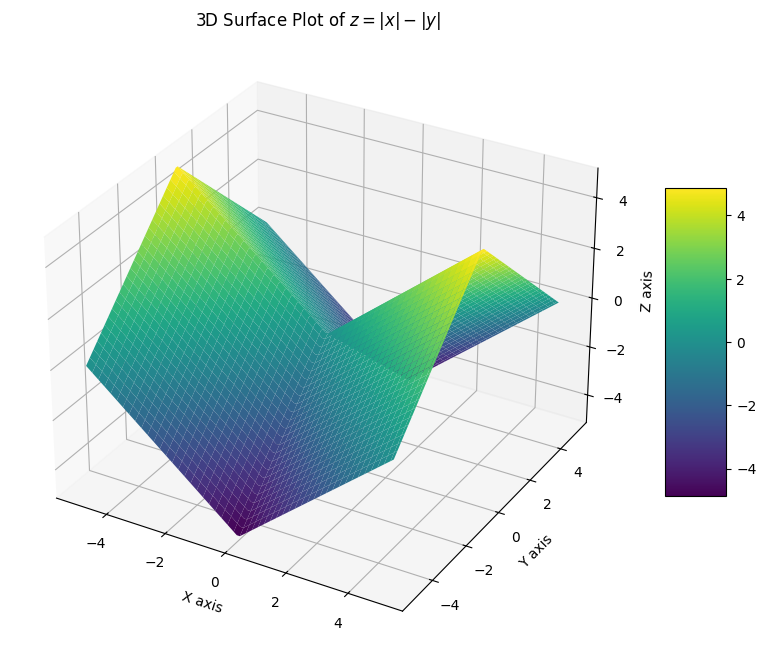

In [73]:
x_range = np.linspace(-5, 5, 100)
y_range = np.linspace(-5, 5, 100)

print(x_range)
print(y_range)

# Repeat the x_range row 100 times vertically
X = np.tile(x_range, (100, 1))

# Repeat the y_range column 100 times horizontally
Y = np.tile(y_range.reshape(-1, 1), (1, 100))

Z = np.abs(X) - np.abs(Y)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, Z, cmap='viridis')

ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')
ax.set_title(r'3D Surface Plot of $z = |x| - |y|$')
fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()

### **Problem-4:** Draw the 3D *Contour plot* of this below equation:

$$z = |x| - |y|$$

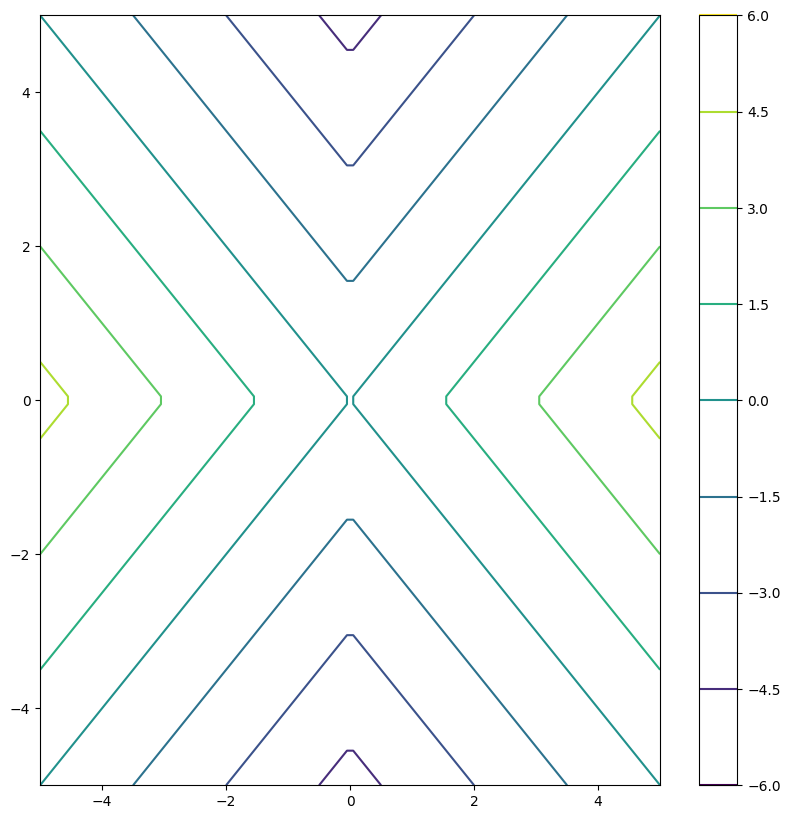

In [74]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot()
p = ax.contour(X,Y,Z,cmap='viridis')
fig.colorbar(p)

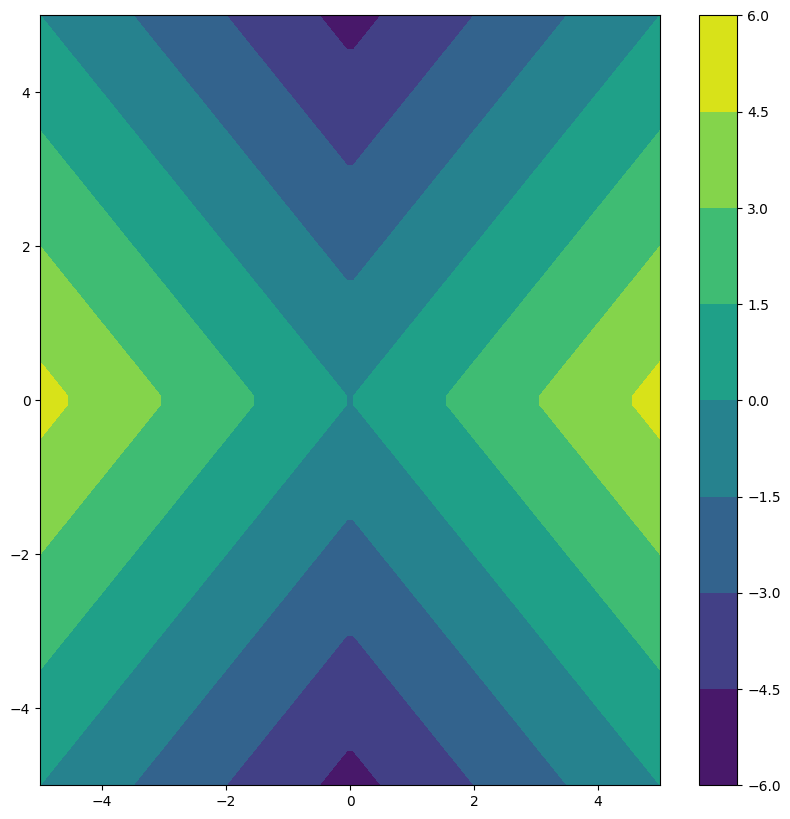

In [75]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot()
p = ax.contourf(X,Y,Z,cmap='viridis')
fig.colorbar(p)

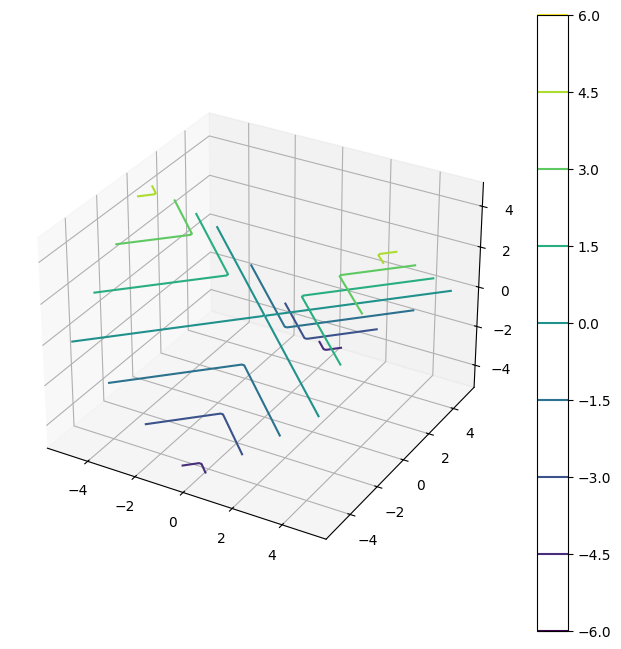

In [76]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot(projection='3d')
p = ax.contour3D(X,Y,Z,cmap='viridis')
fig.colorbar(p)

### **Problem-5:** Draw a second type of Countour plot of the below equation:

$$z = |x| - |y|$$

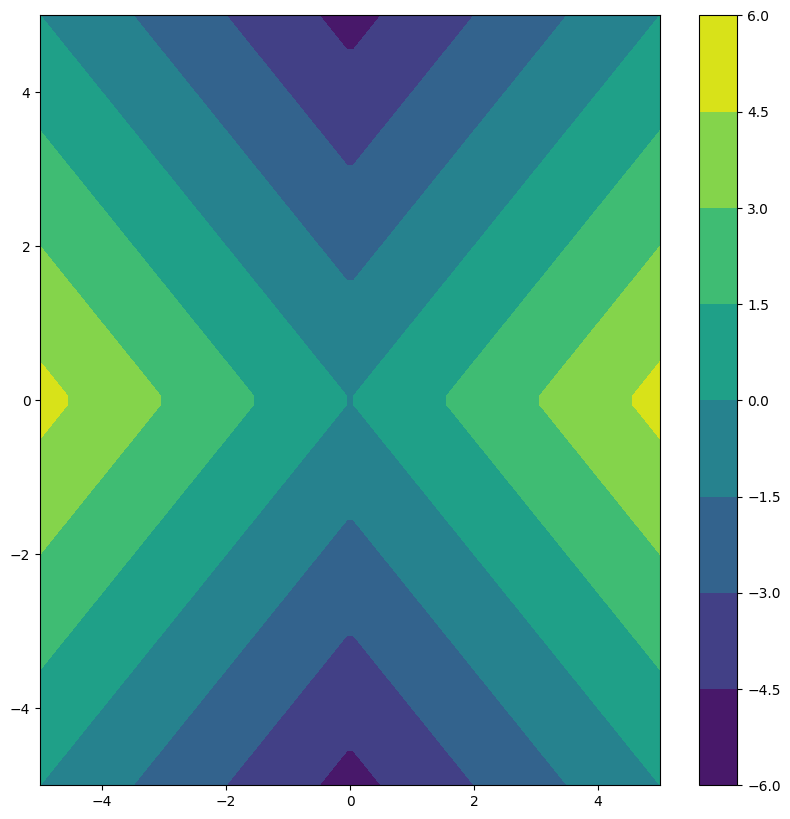

In [77]:
fig = plt.figure(figsize=(10,10))
ax = fig.add_subplot()
p = ax.contourf(X,Y,Z,cmap='viridis')
fig.colorbar(p)

## `Problem 6-7`

Data Set Link - https://docs.google.com/spreadsheets/d/17tUL2yC7MGvo7txuuhLtAI-b6_C4jc0t7FLFxqRm-uI/edit?usp=share_link


**Description of Dataset:**

* Date: It gives the date of which stocks details are given.
* Symbol: Name of stock
* Open: It gives the opening price of stock on that date.
* High: It gives the highest price to which the stock ascened on that day.
* Low: It gives the highest price to which the stock plummeted on that day.
* Close: It gives the closing price of stock on that date.
* Volume: It gives the amount of stock traded on that date.
* VWAP: The volume-weighted average price (VWAP) is a statistic used by traders to determine what the average price is based on both price and volume.
* Turnover:

### `Problem-6` Use Pandas plot functions

* Line plot of closing value of top 5 Stocks in Year 2020.
* Take top 5 stocks based on total turnover in Year 2020

In [78]:
nifty_50 = pd.read_csv('/content/nifty-50 - nifty-50.csv')
nifty_50

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades
0,2000-01-03,HDFCBANK,EQ,157.40,166.00,170.00,166.00,170.00,170.00,169.52,33259.0,5.638122e+11,NaN
1,2000-01-04,HDFCBANK,EQ,170.00,182.00,183.45,171.00,174.00,173.80,174.99,168710.0,2.952261e+12,NaN
2,2000-01-05,HDFCBANK,EQ,173.80,170.00,173.90,165.00,168.00,166.95,169.20,159820.0,2.704094e+12,NaN
3,2000-01-06,HDFCBANK,EQ,166.95,168.00,170.00,165.30,168.95,168.30,168.44,85026.0,1.432166e+12,NaN
4,2000-01-07,HDFCBANK,EQ,168.30,162.15,171.00,162.15,170.75,168.35,166.79,85144.0,1.420158e+12,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
170415,2017-02-16,EICHERMOT,EQ,24750.45,24675.00,25480.00,24666.60,25390.00,25331.30,25152.70,46688.0,1.174329e+14,19201.0
170416,2017-02-17,EICHERMOT,EQ,25331.30,25370.00,25499.90,24720.20,24988.85,25040.30,25022.11,42889.0,1.073173e+14,18653.0
170417,2017-02-20,EICHERMOT,EQ,25040.30,25220.50,25295.00,24800.10,25055.55,25139.05,25116.67,20884.0,5.245366e+13,8152.0
170418,2017-02-21,EICHERMOT,EQ,25139.05,25160.10,25380.00,25047.00,25211.00,25253.50,25214.72,21601.0,5.446631e+13,7423.0


In [79]:
nifty_50.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 170420 entries, 0 to 170419
Data columns (total 13 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   Date        170420 non-null  object 
 1   Symbol      170419 non-null  object 
 2   Series      170419 non-null  object 
 3   Prev Close  170419 non-null  float64
 4   Open        170419 non-null  float64
 5   High        170419 non-null  float64
 6   Low         170419 non-null  float64
 7   Last        170419 non-null  float64
 8   Close       170419 non-null  float64
 9   VWAP        170419 non-null  float64
 10  Volume      170419 non-null  float64
 11  Turnover    170419 non-null  float64
 12  Trades      84925 non-null   float64
dtypes: float64(10), object(3)
memory usage: 16.9+ MB


In [80]:
nifty_50['Date'] = pd.to_datetime(nifty_50['Date'])

In [81]:
nifty_50_2000 = nifty_50[nifty_50['Date'].dt.year == 2020]
nifty_50_2000

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades
4974,2020-01-01,HDFCBANK,EQ,1272.10,1276.10,1280.00,1270.60,1279.00,1278.60,1276.64,1836849.0,2.345001e+14,46625.0
4975,2020-01-02,HDFCBANK,EQ,1278.60,1279.00,1288.00,1279.00,1286.00,1286.75,1284.56,3068583.0,3.941792e+14,104570.0
4976,2020-01-03,HDFCBANK,EQ,1286.75,1282.20,1285.00,1263.60,1268.50,1268.40,1270.48,5427775.0,6.895886e+14,157066.0
4977,2020-01-06,HDFCBANK,EQ,1268.40,1260.00,1261.80,1236.00,1240.25,1240.95,1247.24,5445093.0,6.791348e+14,155007.0
4978,2020-01-07,HDFCBANK,EQ,1240.95,1258.90,1271.45,1252.25,1261.00,1260.60,1261.48,7362247.0,9.287302e+14,189026.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
166068,2020-12-24,DRREDDY,EQ,5224.10,5247.00,5247.00,5165.00,5203.95,5201.80,5198.04,675636.0,3.511984e+14,51937.0
166069,2020-12-28,DRREDDY,EQ,5201.80,5228.15,5235.00,5187.00,5198.00,5201.80,5214.54,411173.0,2.144077e+14,27717.0
166070,2020-12-29,DRREDDY,EQ,5201.80,5225.00,5269.00,5145.60,5155.00,5165.60,5198.60,882433.0,4.587419e+14,69669.0
166071,2020-12-30,DRREDDY,EQ,5165.60,5191.45,5191.45,5142.50,5165.00,5170.95,5162.52,475269.0,2.453587e+14,32851.0


In [82]:
top_5 = nifty_50_2000.groupby('Symbol')['Turnover'].sum().sort_values(ascending=False).head(5).index.to_list()

<Axes: title={'center': 'Closing Value of Top 5 Stocks in 2020 (by Turnover)'}, xlabel='Date', ylabel='Closing Price'>

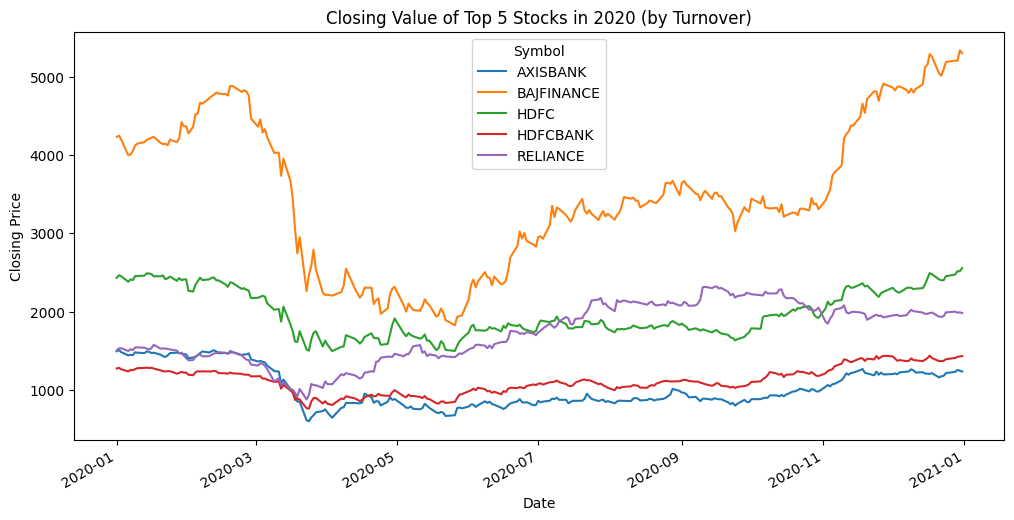

In [83]:
nifty_50_2000[(nifty_50_2000['Symbol'].isin(top_5))].groupby(['Symbol','Date'])['Close'].sum().unstack(level=0).plot(
    figsize=(12, 6),
    title='Closing Value of Top 5 Stocks in 2020 (by Turnover)',
    xlabel='Date',
    ylabel='Closing Price'
)

<Axes: title={'center': 'Closing Value of Top 5 Stocks in 2020 (by Turnover)'}, xlabel='Date', ylabel='Closing Price'>

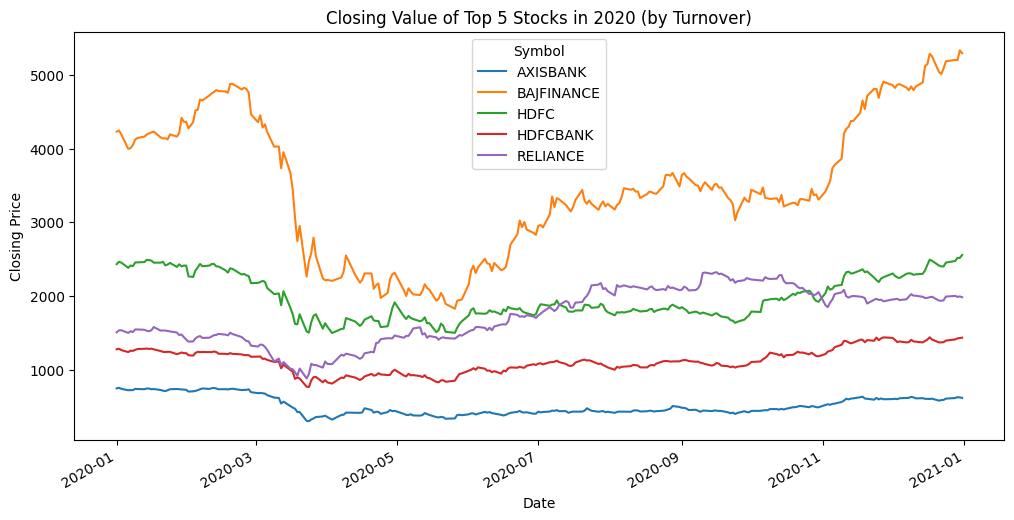

In [84]:
# 1. Get top 5 stocks by total turnover in 2020
top_5 = nifty_50_2000.groupby('Symbol')['Turnover'].sum().sort_values(ascending=False).head(5).index.tolist()

# 2. Filter 2020 data for these top 5 stocks (and optionally filter for EQ series)
top_5_df = nifty_50_2000[(nifty_50_2000['Symbol'].isin(top_5))]

# 3. Use pivot_table instead of pivot
top_5_df.pivot_table(index='Date', columns='Symbol', values='Close', aggfunc='mean').plot(
    figsize=(12, 6),
    title='Closing Value of Top 5 Stocks in 2020 (by Turnover)',
    xlabel='Date',
    ylabel='Closing Price'
)

### `Problem-7` Scatter plot Close price vs Volume for TOP-5 Stocks in year 2021
* Color on Symbol Column

In [85]:
nifty_50_2021 = nifty_50[(nifty_50['Date'].dt.year == 2021)]
nifty_50_2021

,Date,Symbol,Series,Prev Close,Open,High,Low,Last,Close,VWAP,Volume,Turnover,Trades
5226,2021-01-01,HDFCBANK,EQ,1436.30,1440.00,1443.00,1420.60,1423.45,1425.05,1433.57,4405469.0,6.315533e+14,85415.0
5227,2021-01-04,HDFCBANK,EQ,1425.05,1438.00,1438.00,1399.00,1422.25,1416.00,1417.20,7870096.0,1.115350e+15,177576.0
5228,2021-01-05,HDFCBANK,EQ,1416.00,1419.20,1430.75,1409.00,1425.85,1426.70,1419.93,7193412.0,1.021420e+15,186611.0
5229,2021-01-06,HDFCBANK,EQ,1426.70,1435.00,1440.00,1413.10,1419.80,1420.55,1423.55,11067025.0,1.575450e+15,151854.0
5230,2021-01-07,HDFCBANK,EQ,1420.55,1432.50,1432.60,1412.55,1416.90,1416.25,1422.34,9947421.0,1.414860e+15,127305.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
166148,2021-04-26,DRREDDY,EQ,5066.70,5125.00,5130.00,5030.25,5067.00,5066.70,5078.16,950577.0,4.827178e+14,70675.0
166149,2021-04-27,DRREDDY,EQ,5066.70,5090.50,5116.00,5021.35,5062.00,5057.25,5065.33,957835.0,4.851746e+14,64767.0
166150,2021-04-28,DRREDDY,EQ,5057.25,5082.55,5106.90,5030.00,5048.00,5044.45,5065.54,843953.0,4.275075e+14,69716.0
166151,2021-04-29,DRREDDY,EQ,5044.45,5070.25,5144.00,5042.30,5106.00,5102.30,5098.90,1071931.0,5.465666e+14,74199.0


In [86]:
top_5_2021 = nifty_50_2021.groupby('Symbol')['Turnover'].sum().sort_values(ascending=False).head(5).index.tolist()
top_5_2021

['TATAMOTORS', 'AXISBANK', 'ADANIPORTS', 'RELIANCE', 'WIPRO']

In [87]:
top_5_2021_df = nifty_50_2021[(nifty_50_2021['Symbol'].isin(top_5_2021))].groupby(['Symbol','Date'])[['Close','Volume']].mean().unstack(level=0)
top_5_2021_df

Close                                           Volume  \
Symbol     ADANIPORTS AXISBANK RELIANCE TATAMOTORS   WIPRO  ADANIPORTS   
Date                                                                     
2021-01-01     503.85   623.80  1987.50     186.50  388.10   7815730.0   
2021-01-04     498.90   624.70  1990.85     191.30  396.40   9998803.0   
2021-01-05     499.45   664.45  1966.10     193.20  406.30   5135408.0   
2021-01-06     496.80   654.25  1914.25     195.40  406.40   5203982.0   
2021-01-07     513.85   671.10  1911.15     196.75  406.75  10295126.0   
...               ...      ...      ...        ...     ...         ...   
2021-04-26     730.75   700.45  1937.85     295.40  480.30   9390549.0   
2021-04-27     749.15   699.55  1988.65     301.50  485.05  20573107.0   
2021-04-28     746.25   708.15  1997.30     305.90  489.30  11156977.0   
2021-04-29     746.75   719.40  2024.05     301.90  489.85  13851910.0   
2021-04-30     730.05   714.90  1994.50     293.85  492.75  12600934.0   

                                                            
Symbol        AXISBANK    RELIANCE  TATAMOTORS       WIPRO  
Date                                                        
2021-01-01   6047062.0   4622002.0  27334421.0   5042336.0  
2021-01-04  14068156.0  11312992.0  63980597.0   9755721.0  
2021-01-05  37973963.0  11132803.0  75752593.0  25156747.0  
2021-01-06  20829645.0  21414270.0  75621947.0  22486300.0  
2021-01-07  17887570.0  14918406.0  66024848.0  12344755.0  
...                ...         ...         ...         ...  
2021-04-26  21646184.0   9620785.0  30583139.0   9314644.0  
2021-04-27  46559967.0   9226547.0  35040532.0   7209467.0  
2021-04-28  54060587.0   7902002.0  44668126.0   9615534.0  
2021-04-29  25939327.0   8035915.0  36647292.0   7641133.0  
2021-04-30  23011654.0   9150974.0  36121668.0  29115571.0  

[80 rows x 10 columns]

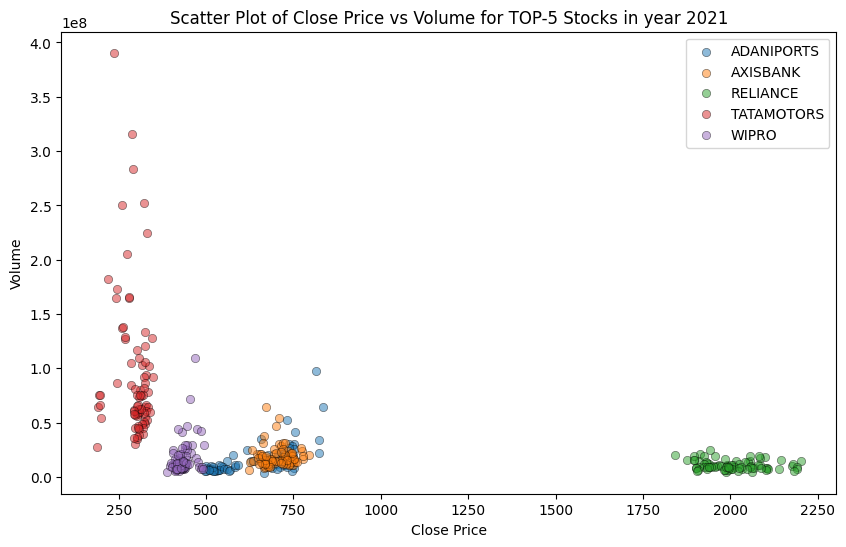

In [88]:
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot()

for symbol in top_5_2021_df['Close'].columns:
	ax.scatter(
		top_5_2021_df['Close'][symbol],
		top_5_2021_df['Volume'][symbol],
    label=symbol,
    alpha=0.5,
    edgecolors='black',
    linewidth=0.5
)
ax.legend(top_5_2021_df['Close'].columns)
ax.set_title('Scatter Plot of Close Price vs Volume for TOP-5 Stocks in year 2021')
ax.set_xlabel('Close Price')
ax.set_ylabel('Volume')

plt.show()

### `Problem-8` Create a 3-D Scatter Plot using `time,x,y` on below synthetic data. and give color gradiant on `z`
```
# Create a 3D dataset
time = np.linspace(0, 10, 100)
x = np.sin(time)
y = np.cos(time)
z = time

# Create a DataFrame from the dataset
data = pd.DataFrame({'time': time, 'x': x, 'y': y, 'z': z})
```

In [89]:
time = np.linspace(0, 10, 100)
x = np.sin(time)
y = np.cos(time)
z = time

data = pd.DataFrame({'time': time, 'x': x, 'y': y, 'z': z})

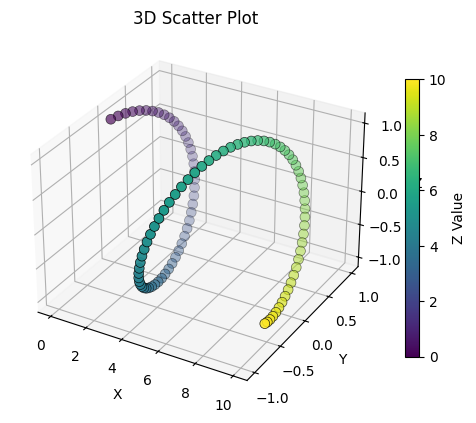

In [90]:
fig = plt.figure(figsize=(6,6))
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(data['time'],data['x'],data['y'],c=data['z'],cmap='viridis',s=50,edgecolor='k',linewidth=0.5)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('3D Scatter Plot')

fig.colorbar(scatter, ax=ax, label='Z Value', shrink=0.6)

In [91]:
# Create 2D coordinate matrices (100 x 100)
x_2d = np.tile(x, (100, 1))                  # Shape: (100, 100)
y_2d = np.tile(y.reshape(-1, 1), (1, 100))   # Shape: (100, 100)

# Broadcast z into a (100, 100) matrix corresponding to the points
z_2d = np.tile(z, (100, 1))                  # Shape: (100, 100)

Text(0.5, 1.0, 'Contourf Plot using Reshape & Tile Logic')

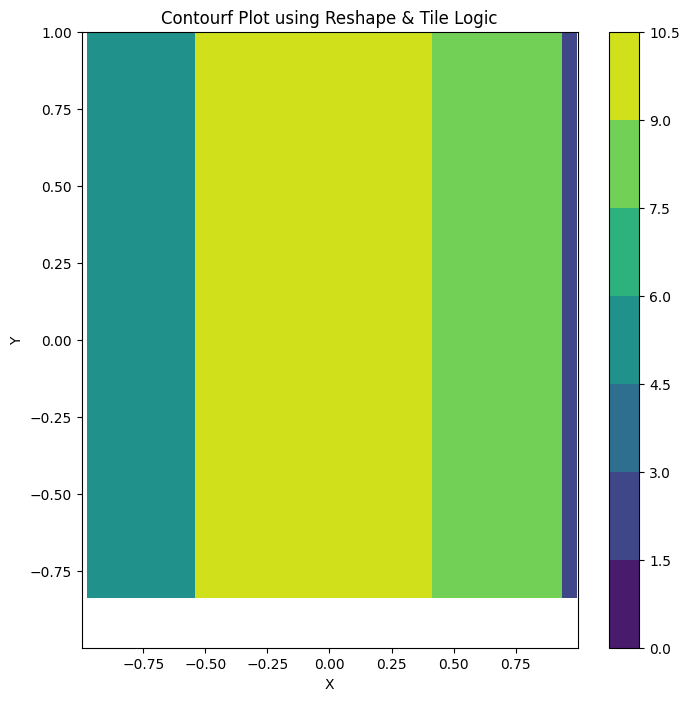

In [92]:
fig = plt.figure(figsize=(8,8))
ax = fig.add_subplot()
p = ax.contourf(x_2d, y_2d, z_2d, cmap='viridis')
fig.colorbar(p)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_title('Contourf Plot using Reshape & Tile Logic')

### `Problem 9:` Create a surface plot and the 2 types of the contour plots of the below equation.

$$z = sin(\sqrt{x^2 + y^2})$$


In [93]:
a = np.linspace(-50,50,100)
b = np.linspace(-50,50,100)

aa = np.tile(a, (100,1))
print(aa.shape)
bb = np.tile(b.reshape(100,1), (1,100))
print(bb.shape)

(100, 100)
(100, 100)


In [94]:
z = np.sin(np.sqrt((aa**2) + (bb**2)))
z

array([[ 0.99969142,  0.77393684,  0.18086552, ...,  0.18086552,
         0.77393684,  0.99969142],
       [ 0.77393684,  0.16636406, -0.51703907, ..., -0.51703907,
         0.16636406,  0.77393684],
       [ 0.18086552, -0.51703907, -0.95250457, ..., -0.95250457,
        -0.51703907,  0.18086552],
       ...,
       [ 0.18086552, -0.51703907, -0.95250457, ..., -0.95250457,
        -0.51703907,  0.18086552],
       [ 0.77393684,  0.16636406, -0.51703907, ..., -0.51703907,
         0.16636406,  0.77393684],
       [ 0.99969142,  0.77393684,  0.18086552, ...,  0.18086552,
         0.77393684,  0.99969142]])

Text(0.5, 0, 'Z axis')

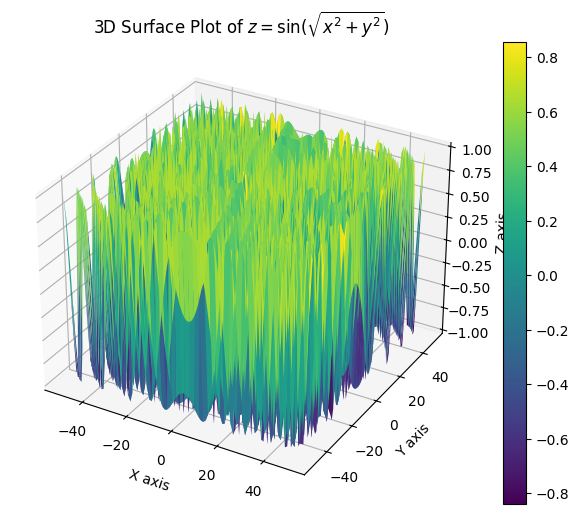

In [95]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(aa,bb,z, cmap='viridis')
fig.colorbar(surf)

ax.set_title(r"3D Surface Plot of $z = \sin(\sqrt{x^2 + y^2})$")
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')

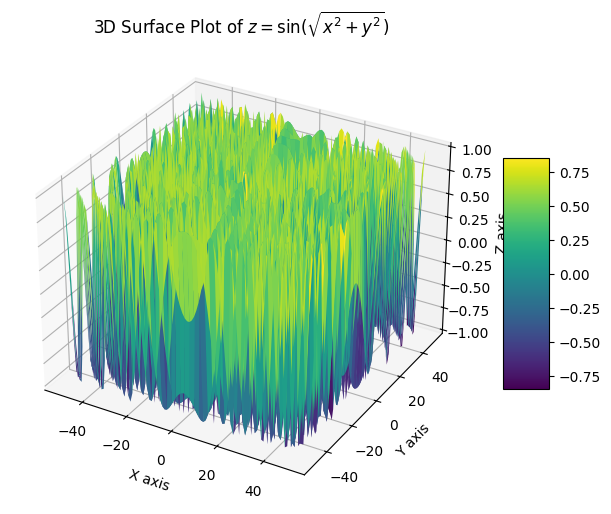

In [96]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Create 1D range vectors
x = np.linspace(-50, 50, 100)
y = np.linspace(-50, 50, 100)

# 2. Create 2D coordinate matrices
X, Y = np.meshgrid(x, y)

# 3. Compute 2D Z values
Z = np.sin(np.sqrt(X**2 + Y**2))

# 4. Plot the 3D surface
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

surf = ax.plot_surface(X, Y, Z, cmap="viridis")
fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_zlabel("Z axis")
ax.set_title(r"3D Surface Plot of $z = \sin(\sqrt{x^2 + y^2})$")

plt.show()

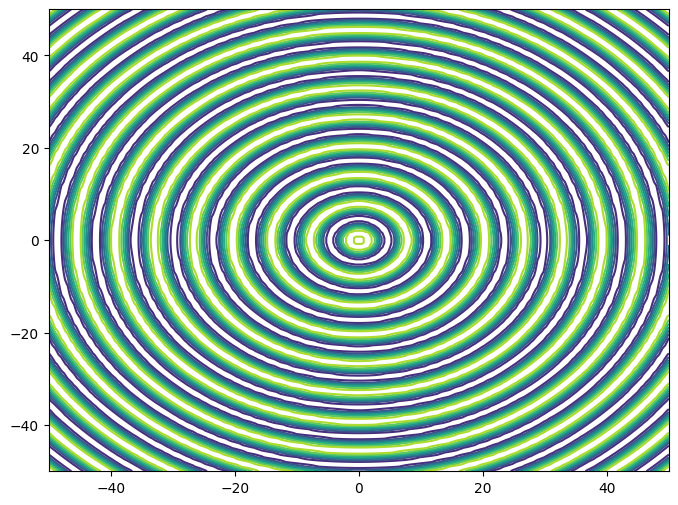

In [97]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot()
ax.contour(X, Y, Z, cmap='viridis')

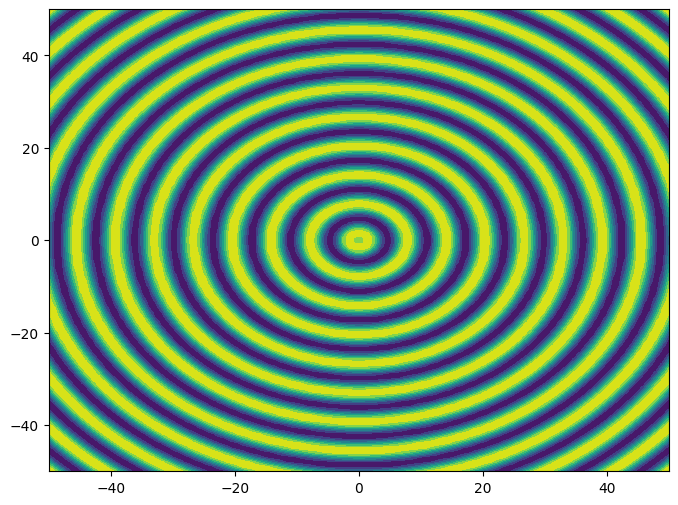

In [98]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot()
ax.contourf(X, Y, Z, cmap='viridis')

### `Problem 10:` Create a surface plot and the 2 types of the contour plots of the below equation.

$$z = tan(\log_2({x^2 + y^2})$$

Text(0.5, 0.92, '3D Surface Plot of $z = \\tan(\\log_2{(x^2 + y^2)})$')

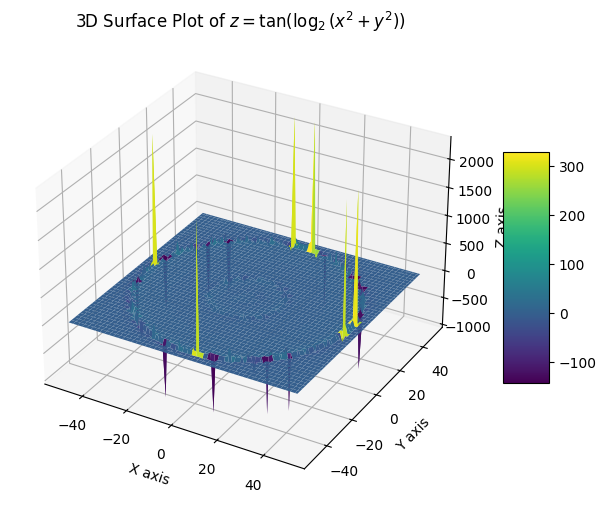

In [99]:
x = np.linspace(-50, 50, 100)
y = np.linspace(-50, 50, 100)

X, Y = np.meshgrid(x, y)

Z = np.tan(np.log2(X**2 + Y**2))
## Z[np.abs(Z) > 10] = np.nan

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

surf = ax.plot_surface(X, Y, Z, cmap="viridis")
fig.colorbar(surf, shrink=0.5, aspect=5)

## ax.set_zlim(-10, 10)
ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_zlabel("Z axis")
ax.set_title(r"3D Surface Plot of $z = \tan(\log_2{(x^2 + y^2)})$")

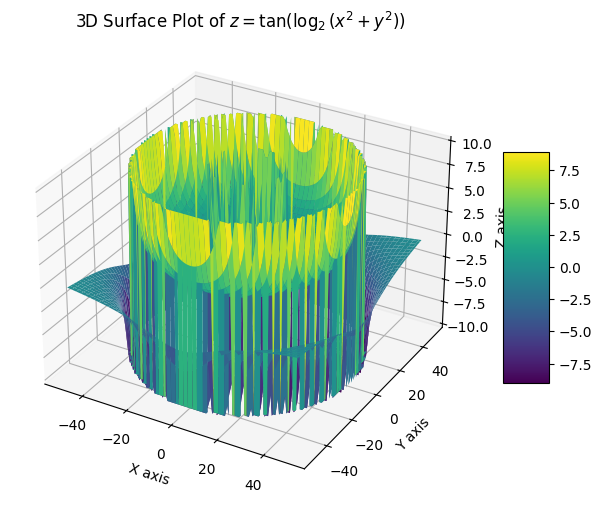

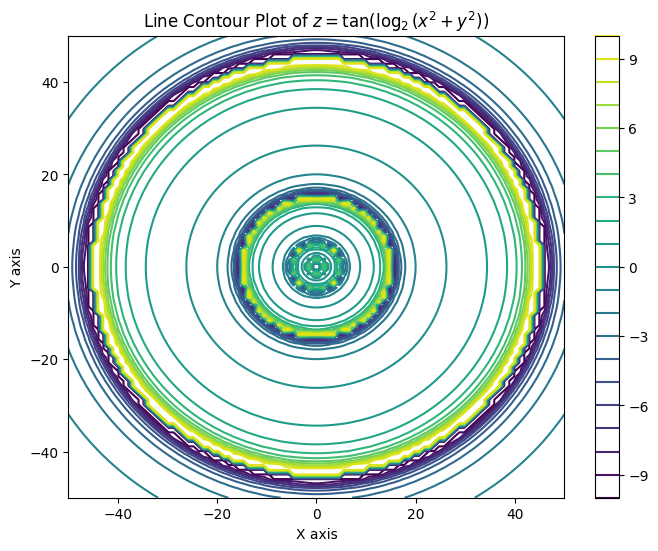

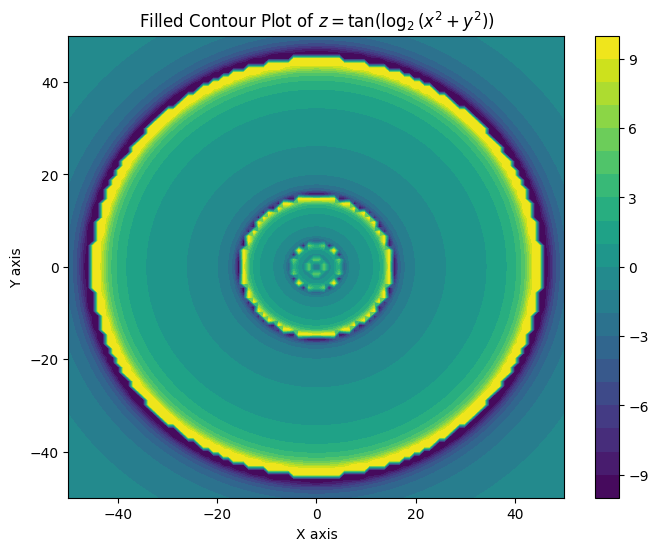

In [100]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Setup Grid
x = np.linspace(-50, 50, 100)
y = np.linspace(-50, 50, 100)
X, Y = np.meshgrid(x, y)

# 2. Compute Z and clip asymptotic values for clean rendering
R2 = X**2 + Y**2
R2[R2 == 0] = 1e-10  # Prevent log2(0) division error
Z = np.clip(np.tan(np.log2(R2)), -10, 10)

# --------------------------------------------------
# Part 1: 3D Surface Plot
# --------------------------------------------------
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
surf = ax.plot_surface(X, Y, Z, cmap="viridis")
fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_zlabel("Z axis")
ax.set_title(r"3D Surface Plot of $z = \tan(\log_2(x^2 + y^2))$")
plt.show()

# --------------------------------------------------
# Part 2: Contour Plot Type 1 (Line Contour)
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
cp = ax.contour(X, Y, Z, levels=20, cmap="viridis")
fig.colorbar(cp)
ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_title(r"Line Contour Plot of $z = \tan(\log_2(x^2 + y^2))$")
plt.show()

# --------------------------------------------------
# Part 3: Contour Plot Type 2 (Filled Contour)
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 6))
cpf = ax.contourf(X, Y, Z, levels=20, cmap="viridis")
fig.colorbar(cpf)
ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_title(r"Filled Contour Plot of $z = \tan(\log_2(x^2 + y^2))$")
plt.show()

In [101]:
a = np.linspace(-50,50,100)
b = np.linspace(-50,50,100)

aa = np.tile(a, (100,1))
print(aa.shape)
bb = np.tile(b.reshape(100,1), (1,100))
print(bb.shape)

(100, 100)
(100, 100)


In [102]:
z = np.tan(np.log2(aa**2 + bb**2))
z

array([[-0.28610217, -0.3179052 , -0.35028938, ..., -0.35028938,
        -0.3179052 , -0.28610217],
       [-0.3179052 , -0.35097796, -0.38474867, ..., -0.38474867,
        -0.35097796, -0.3179052 ],
       [-0.35028938, -0.38474867, -0.42003796, ..., -0.42003796,
        -0.38474867, -0.35028938],
       ...,
       [-0.35028938, -0.38474867, -0.42003796, ..., -0.42003796,
        -0.38474867, -0.35028938],
       [-0.3179052 , -0.35097796, -0.38474867, ..., -0.38474867,
        -0.35097796, -0.3179052 ],
       [-0.28610217, -0.3179052 , -0.35028938, ..., -0.35028938,
        -0.3179052 , -0.28610217]])

In [103]:
z.shape

(100, 100)

Text(0.5, 0, 'Z axis')

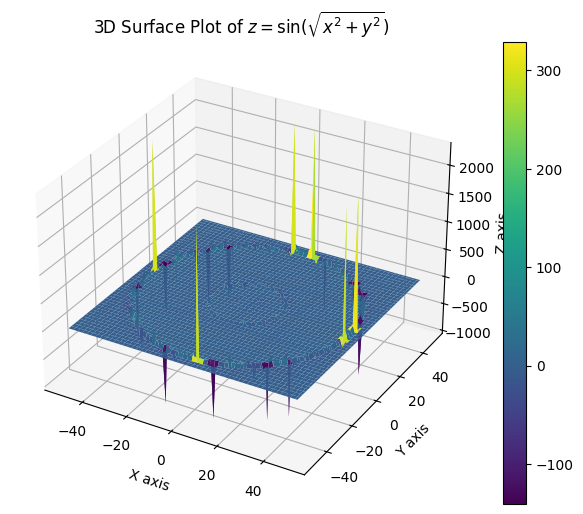

In [104]:
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(projection='3d')

surf = ax.plot_surface(aa,bb,z, cmap='viridis')
fig.colorbar(surf)

ax.set_title(r"3D Surface Plot of $z = \sin(\sqrt{x^2 + y^2})$")
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')

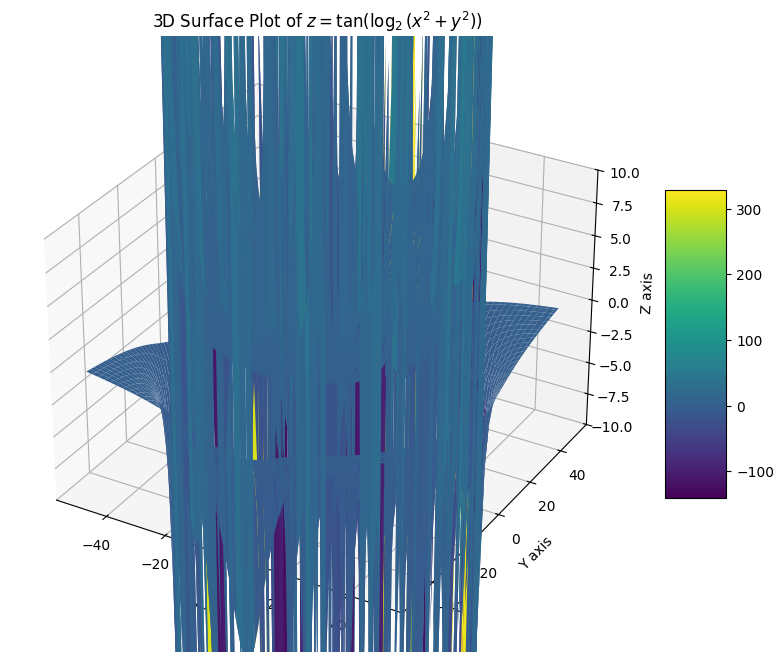

In [105]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Create 1D range vectors (avoiding 0 to prevent log2(0) division by zero)
x = np.linspace(-50, 50, 100)
y = np.linspace(-50, 50, 100)

# 2. Create 2D coordinate matrices
X, Y = np.meshgrid(x, y)

# 3. Compute Z for z = tan(log2(x^2 + y^2))
Z = np.tan(np.log2(X**2 + Y**2))
## Z[np.abs(Z) > 10] = np.nan

# 4. Plot the 3D surface
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")

surf = ax.plot_surface(X, Y, Z, cmap="viridis")
fig.colorbar(surf, shrink=0.5, aspect=5)

## ax.set_zlim(-10, 10)
ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_zlabel("Z axis")
ax.set_title(r"3D Surface Plot of $z = \tan(\log_2(x^2 + y^2))$")

# Set Z limits to manage asymptotic spikes from tangent function
ax.set_zlim(-10, 10)

plt.show()

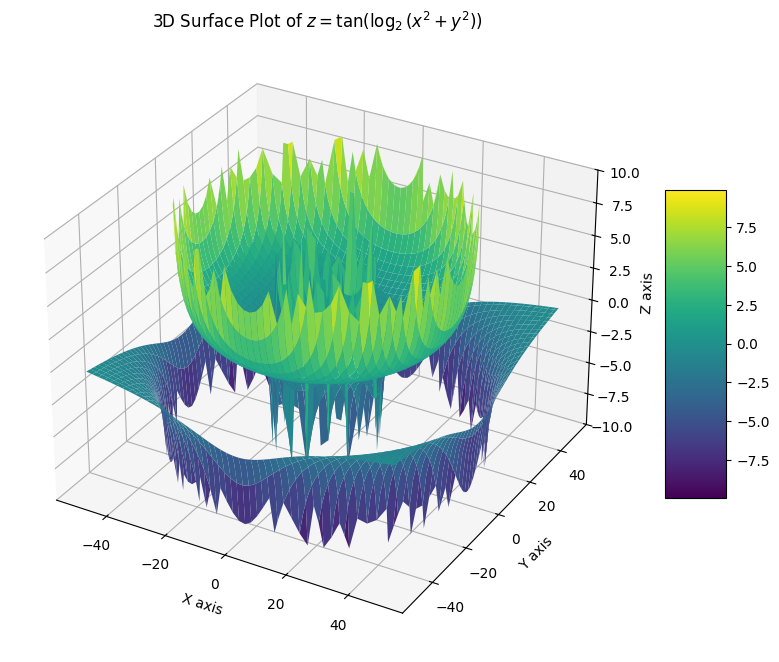

In [106]:
import matplotlib.pyplot as plt
import numpy as np

x = np.linspace(-50, 50, 100)
y = np.linspace(-50, 50, 100)

X, Y = np.meshgrid(x, y)

Z = np.tan(np.log2(X**2 + Y**2))

# Hide values near the vertical asymptotes
Z[np.abs(Z) > 10] = np.nan

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")

surf = ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="none"
)

fig.colorbar(surf, shrink=0.5, aspect=5)

ax.set_xlabel("X axis")
ax.set_ylabel("Y axis")
ax.set_zlabel("Z axis")

ax.set_title(
    r"3D Surface Plot of $z = \tan(\log_2(x^2 + y^2))$"
)

ax.set_zlim(-10, 10)

plt.show()